In [1]:

# CodeAlpha Data Analytics Internship
# Task 4: Sentiment Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("CodeAlpha - Task 4: Sentiment Analysis")
print("Libraries imported successfully.")


CodeAlpha - Task 4: Sentiment Analysis
Libraries imported successfully.


In [2]:

# Download the NLTK movie reviews dataset
import nltk

nltk.download("movie_reviews")
nltk.download("punkt")

from nltk.corpus import movie_reviews

# Convert the reviews into a DataFrame
reviews = []

for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        text = movie_reviews.raw(fileid)

        reviews.append({
            "review": text,
            "label": category
        })

reviews_df = pd.DataFrame(reviews)

print("Dataset loaded successfully!")
print("Dataset shape:", reviews_df.shape)
print("\nLabel distribution:")
print(reviews_df["label"].value_counts())

display(reviews_df.head())


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Dataset loaded successfully!
Dataset shape: (2000, 2)

Label distribution:
label
neg    1000
pos    1000
Name: count, dtype: int64


,review,label
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard's quick movie review \ndamn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' firs...",neg
4,synopsis : a mentally unstable man undergoing ...,neg


In [3]:

# Initialize VADER sentiment analyzer
import nltk
nltk.download("vader_lexicon")

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

print("VADER sentiment analyzer initialized successfully!")

# Test it with one example
example = "This movie was wonderful and I really enjoyed it."
print("\nExample review:", example)
print("Sentiment scores:", sia.polarity_scores(example))


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


VADER sentiment analyzer initialized successfully!

Example review: This movie was wonderful and I really enjoyed it.
Sentiment scores: {'neg': 0.0, 'neu': 0.451, 'pos': 0.549, 'compound': 0.807}


In [4]:

# Apply VADER sentiment analysis to all reviews

def get_sentiment(text):
    scores = sia.polarity_scores(text)
    compound = scores["compound"]

    if compound >= 0.05:
        return "pos"
    elif compound <= -0.05:
        return "neg"
    else:
        return "neu"

# Predict sentiment for every review
reviews_df["predicted_sentiment"] = reviews_df["review"].apply(
    get_sentiment
)

print("Sentiment analysis completed!")

print("\nPredicted sentiment distribution:")
print(reviews_df["predicted_sentiment"].value_counts())

display(
    reviews_df[
        ["review", "label", "predicted_sentiment"]
    ].head(10)
)


Sentiment analysis completed!

Predicted sentiment distribution:
predicted_sentiment
pos    1382
neg     617
neu       1
Name: count, dtype: int64


,review,label,predicted_sentiment
0,"plot : two teen couples go to a church party ,...",neg,pos
1,the happy bastard's quick movie review \ndamn ...,neg,pos
2,it is movies like these that make a jaded movi...,neg,pos
3,""" quest for camelot "" is warner bros . ' firs...",neg,neg
4,synopsis : a mentally unstable man undergoing ...,neg,pos
5,capsule : in 2176 on the planet mars police ta...,neg,neg
6,"so ask yourself what "" 8mm "" ( "" eight millime...",neg,neg
7,that's exactly how long the movie felt to me ....,neg,pos
8,call it a road trip for the walking wounded . ...,neg,neg
9,plot : a young french boy sees his parents kil...,neg,pos


Binary evaluation coverage: 1999/2000 reviews
Accuracy on non-neutral predictions: 63.53%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.72      0.44      0.55      1000
    Positive       0.60      0.83      0.69       999

    accuracy                           0.64      1999
   macro avg       0.66      0.64      0.62      1999
weighted avg       0.66      0.64      0.62      1999



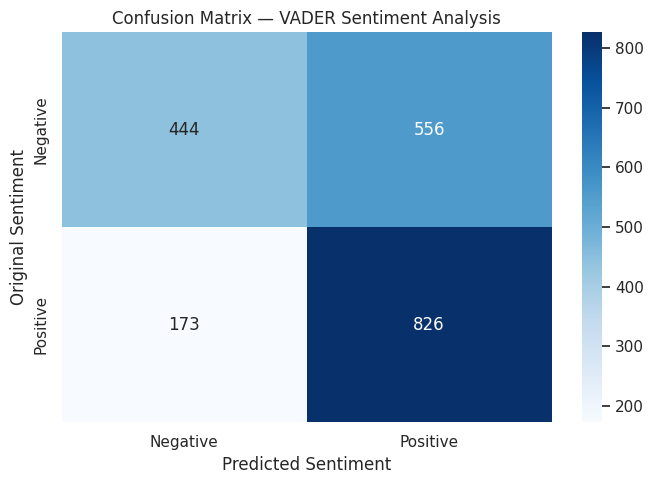

In [5]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Original labels contain only pos and neg.
# Exclude neutral predictions for binary evaluation.
binary_df = reviews_df[
    reviews_df["predicted_sentiment"].isin(["pos", "neg"])
].copy()

y_true = binary_df["label"]
y_pred = binary_df["predicted_sentiment"]

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print(f"Binary evaluation coverage: {len(binary_df)}/{len(reviews_df)} reviews")
print(f"Accuracy on non-neutral predictions: {accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=["neg", "pos"],
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

# Create a confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["neg", "pos"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix — VADER Sentiment Analysis")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Original Sentiment")
plt.tight_layout()
plt.show()


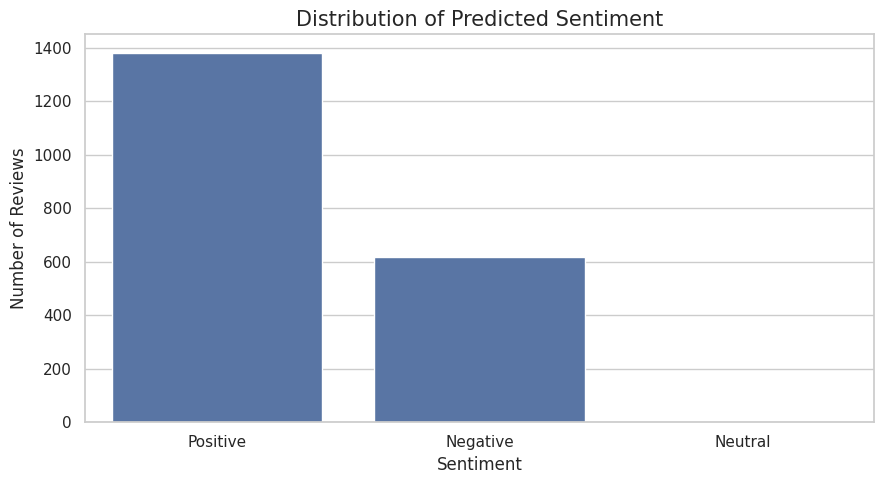

,Sentiment,Count
0,Positive,1382
1,Negative,617
2,Neutral,1


In [6]:

# Visualization 1: Predicted Sentiment Distribution

sentiment_counts = (
    reviews_df["predicted_sentiment"]
    .value_counts()
    .reindex(["pos", "neg", "neu"], fill_value=0)
    .rename_axis("Sentiment")
    .reset_index(name="Count")
)

sentiment_labels = {
    "pos": "Positive",
    "neg": "Negative",
    "neu": "Neutral"
}

sentiment_counts["Sentiment"] = (
    sentiment_counts["Sentiment"].map(sentiment_labels)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=sentiment_counts,
    x="Sentiment",
    y="Count"
)

plt.title("Distribution of Predicted Sentiment", fontsize=15)
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

Path("outputs").mkdir(exist_ok=True)
plt.savefig(
    "outputs/sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
display(sentiment_counts)


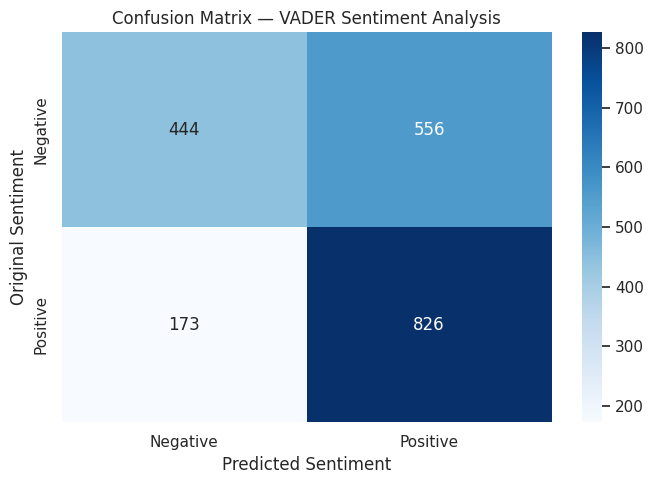

Sentiment analysis outputs saved successfully!

Files in outputs folder:
classification_report.csv
confusion_matrix.csv
confusion_matrix.png
evaluation_summary.csv
sentiment_distribution.png
sentiment_predictions.csv


In [7]:

# Save confusion matrix as a separate image
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix — VADER Sentiment Analysis")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Original Sentiment")
plt.tight_layout()

plt.savefig(
    "outputs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save predictions and evaluation results
reviews_df.to_csv("outputs/sentiment_predictions.csv", index=False)

report = classification_report(
    y_true,
    y_pred,
    labels=["neg", "pos"],
    target_names=["Negative", "Positive"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "outputs/classification_report.csv"
)

pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
).to_csv("outputs/confusion_matrix.csv")

pd.DataFrame([{
    "total_reviews": len(reviews_df),
    "non_neutral_predictions": len(binary_df),
    "neutral_predictions": len(reviews_df) - len(binary_df),
    "accuracy_non_neutral": accuracy
}]).to_csv("outputs/evaluation_summary.csv", index=False)

print("Sentiment analysis outputs saved successfully!")
print("\nFiles in outputs folder:")
for file in sorted(Path("outputs").glob("*")):
    print(file.name)
